<a href="https://colab.research.google.com/github/Simranpande/retail-demand-forecasting/blob/main/notebooks/03_decomposition_baselines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/retail-demand-forecasting/data/"
df = pd.read_parquet(BASE + "processed/m5_ca1_top100.parquet")

Mounted at /content/drive


73 of 100 items have full history
0 missing dates


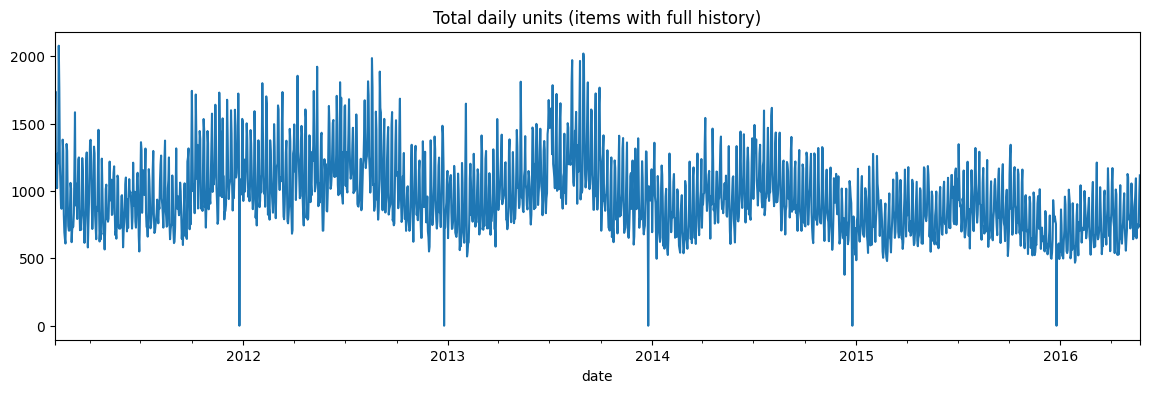

In [2]:
counts = df.groupby("id").size()
full_ids = counts[counts == counts.max()].index
print(f"{len(full_ids)} of 100 items have full history")

daily = (df[df["id"].isin(full_ids)]
         .groupby("date")["units"].sum()
         .asfreq("D"))
print(daily.isna().sum(), "missing dates")   # should be 0
daily.plot(figsize=(14, 4), title="Total daily units (items with full history)")
plt.show()

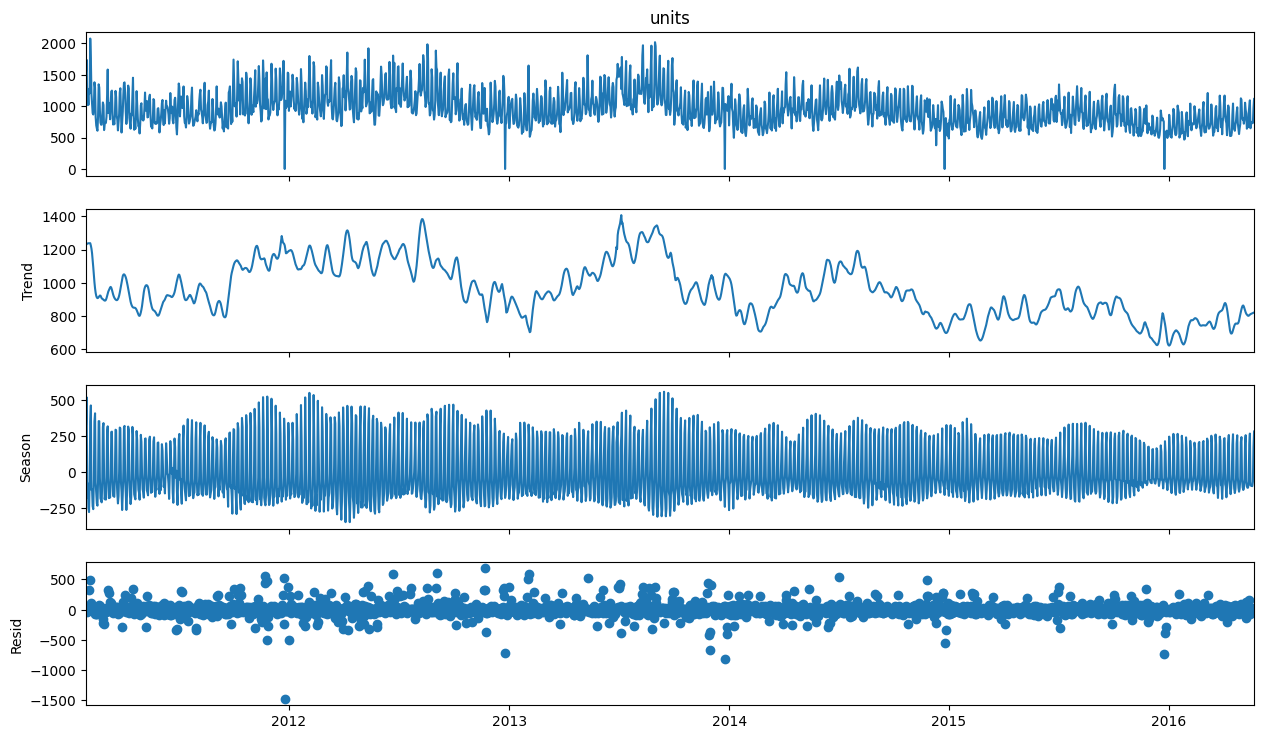

In [3]:
from statsmodels.tsa.seasonal import STL

stl = STL(daily, period=7, robust=True).fit()
fig = stl.plot()
fig.set_size_inches(14, 8)
plt.show()

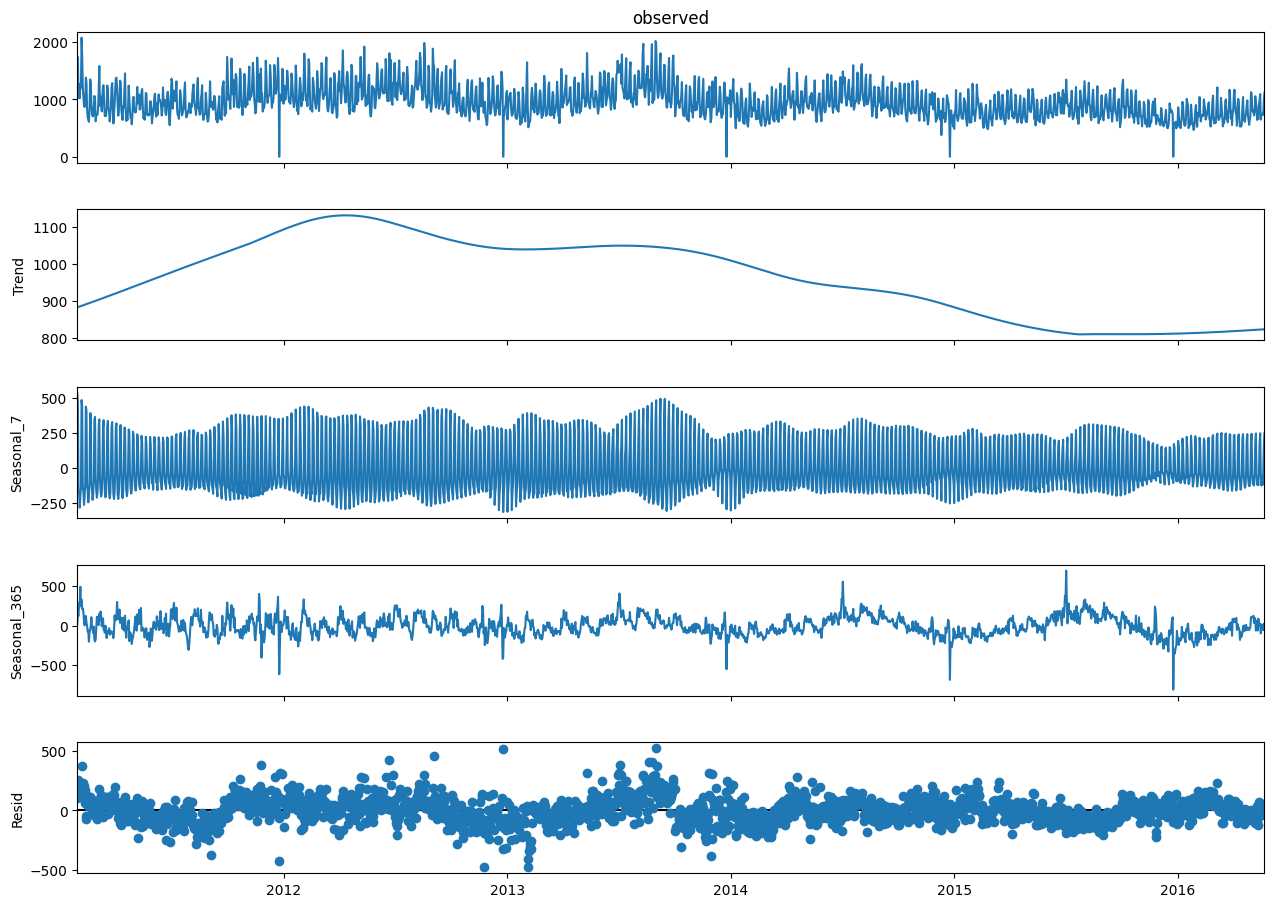

In [4]:
from statsmodels.tsa.seasonal import MSTL

res = MSTL(daily, periods=(7, 365)).fit()
fig = res.plot()
fig.set_size_inches(14, 10)
plt.show()

In [5]:
from statsmodels.tsa.stattools import adfuller

for name, s in [("original", daily), ("differenced", daily.diff().dropna())]:
    stat, p, *_ = adfuller(s)
    print(f"{name}: ADF stat = {stat:.3f}, p-value = {p:.4f}")

original: ADF stat = -2.524, p-value = 0.1097
differenced: ADF stat = -17.200, p-value = 0.0000


/tmp/ipykernel_502/4230871552.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, *_ = adfuller(s)
/tmp/ipykernel_502/4230871552.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, *_ = adfuller(s)


In [6]:
TEST_DAYS = 28
train, test = daily[:-TEST_DAYS], daily[-TEST_DAYS:]

def wape(y, yhat):
    return np.abs(y - yhat).sum() / np.abs(y).sum()

def rmse(y, yhat):
    return np.sqrt(np.mean((y - yhat) ** 2))

results = {}

In [7]:
snaive = pd.Series(np.tile(train[-7:].values, TEST_DAYS // 7), index=test.index)
results["Seasonal naive"] = (wape(test, snaive), rmse(test, snaive))

In [8]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
sarima = model.forecast(TEST_DAYS)
results["SARIMA(1,1,1)(1,1,1,7)"] = (wape(test, sarima), rmse(test, sarima))

                         WAPE     RMSE
Seasonal naive          0.111   57.628
SARIMA(1,1,1)(1,1,1,7)  0.101  101.135


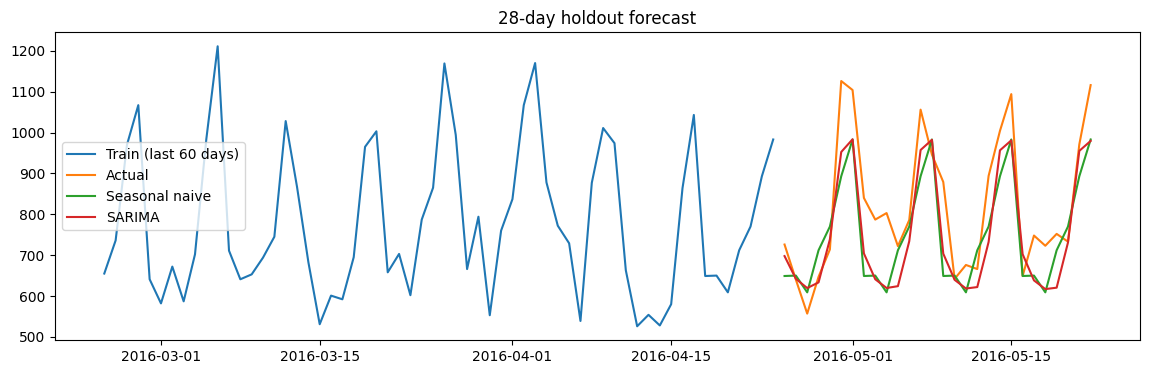

In [9]:
table = pd.DataFrame(results, index=["WAPE", "RMSE"]).T.round(3)
print(table)

plt.figure(figsize=(14, 4))
plt.plot(train[-60:], label="Train (last 60 days)")
plt.plot(test, label="Actual")
plt.plot(snaive, label="Seasonal naive")
plt.plot(sarima, label="SARIMA")
plt.legend(); plt.title("28-day holdout forecast"); plt.show()